# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [4]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
# Inspect the shapes of the datasets


# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical



In [8]:
import matplotlib.pyplot as plt
# Verify the data looks as expected


Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here**

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [12]:
from modulefinder import test

from keras.models import Sequential
from keras.layers import Dense, Flatten

y_test_oh = to_categorical(y_test, num_classes=10)
y_train_oh = to_categorical(y_train, num_classes=10)

# Create a simple linear regression model

model = Sequential()
model.add(Flatten(input_shape=(28, 28)))  # Flatten the input images
model.add(Dense(128, activation='relu'))  # Hidden layer with 128 neurons and ReLU activation
model.add(Dense(10, activation='softmax'))  # Output layer with 10 neurons and softmax activation

# Compile the model using `model.compile()`

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model with `model.fit()`

history = model.fit(X_train, y_train_oh, epochs=10, batch_size=32, validation_split=0.2)

# Evaluate the model with `model.evaluate()`

test_loss, test_accuracy = model.evaluate(X_test, y_test_oh)
print (f'Test accuracy: {test_accuracy:.4f}')
print (f'Test loss: {test_loss:.4f}')

c:\Users\param\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8219 - loss: 0.5148 - val_accuracy: 0.8561 - val_loss: 0.4051
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 934us/step - accuracy: 0.8592 - loss: 0.3887 - val_accuracy: 0.8700 - val_loss: 0.3649
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 924us/step - accuracy: 0.8738 - loss: 0.3476 - val_accuracy: 0.8640 - val_loss: 0.3739
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 907us/step - accuracy: 0.8816 - loss: 0.3212 - val_accuracy: 0.8751 - val_loss: 0.3471
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 932us/step - accuracy: 0.8888 - loss: 0.3012 - val_accuracy: 0.8795 - val_loss: 0.3319
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 920us/step - accuracy: 0.8938 - loss: 0.2844 - val_accuracy: 0.8708 - val_loss: 0.3580
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 919us/step - accuracy: 0.8992 - loss: 0.2732 - val_accuracy: 0.8873 - val_loss: 0.3128
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 935us/step - accuracy: 0.9015 - l

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here**

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [14]:
from keras.layers import Conv2D
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))  # Output layer with 10 neurons and softmax activation

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train_oh, epochs=10, batch_size=32, validation_split=0.2)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test_oh)
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test loss: {test_loss:.4f}')

Epoch 1/10


c:\Users\param\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8527 - loss: 0.4150 - val_accuracy: 0.8799 - val_loss: 0.3352
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9004 - loss: 0.2779 - val_accuracy: 0.8998 - val_loss: 0.2777
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9159 - loss: 0.2310 - val_accuracy: 0.9101 - val_loss: 0.2519
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9288 - loss: 0.1939 - val_accuracy: 0.9081 - val_loss: 0.2608
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9387 - loss: 0.1669 - val_accuracy: 0.9154 - val_loss: 0.2459
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9484 - loss: 0.1419 - val_accuracy: 0.9168 - val_loss: 0.2513
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9553 - loss: 0.1218 - val_accuracy: 0.9159 - val_loss: 0.2689
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9627 - loss: 0.1021 - val_accurac

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here**

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def build_cnn_model(filters, dropout_rate, input_shape=(28, 28, 1), num_classes=10):
    model = Sequential()
    model.add(Conv2D(filters, kernel_size=(3, 3), activation='relu', input_shape=input_shape))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(dropout_rate))   # rate 0.0 = no dropout
    model.add(Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

filter_values = [16, 32, 64]
dropout_options = [0.0, 0.5]   # absent vs. present

results = []
histories = {}

for dropout_rate in dropout_options:
    for filters in filter_values:
        print(f'Training model with {filters} filters and dropout rate of {dropout_rate}')
        model = build_cnn_model(filters, dropout_rate)   # fresh model each run

        history = model.fit(
            X_train, y_train_oh,
            epochs=10,
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
        histories[(filters, dropout_rate)] = history.history

        results.append({
            "filters": filters,
            "dropout": dropout_rate,
            "train_acc": history.history["accuracy"][-1],
            "val_acc": history.history["val_accuracy"][-1],
            "test_loss": test_loss,
            "test_acc": test_acc,
        })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

Training model with 16 filters and dropout rate of 0.0


c:\Users\param\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training model with 32 filters and dropout rate of 0.0
Training model with 64 filters and dropout rate of 0.0
Training model with 16 filters and dropout rate of 0.5
Training model with 32 filters and dropout rate of 0.5
Training model with 64 filters and dropout rate of 0.5
 filters  dropout  train_acc  val_acc  test_loss  test_acc
      16      0.0     0.9653   0.9146     0.3037    0.9083
      32      0.0     0.9743   0.9133     0.3276    0.9122
      64      0.0     0.9803   0.9174     0.3592    0.9154
      16      0.5     0.9202   0.9125     0.2568    0.9087
      32      0.5     0.9244   0.9167     0.2627    0.9086
      64      0.5     0.9312   0.9153     0.2649    0.9097


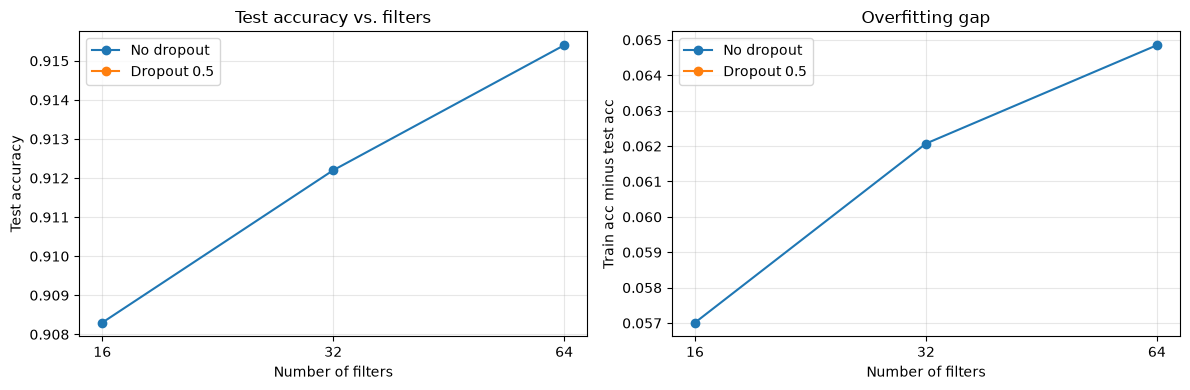

In [24]:
# B. Test presence or absence of regularization

# Visualize: test accuracy by number of filters, with and without dropout
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for use_dropout, label in [(False, "No dropout"), (True, "Dropout 0.5")]:
    subset = results_df[results_df["dropout"] == use_dropout]
    axes[0].plot(subset["filters"], subset["test_acc"], marker="o", label=label)

axes[0].set_xscale("log", base=2)
axes[0].set_xticks(filter_values)
axes[0].set_xticklabels(filter_values)
axes[0].set_xlabel("Number of filters")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy vs. filters")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Train vs. test gap shows the effect of regularization
for use_dropout, label in [(False, "No dropout"), (True, "Dropout 0.5")]:
    subset = results_df[results_df["dropout"] == use_dropout]
    gap = subset["train_acc"] - subset["test_acc"]
    axes[1].plot(subset["filters"], gap, marker="o", label=label)

axes[1].set_xscale("log", base=2)
axes[1].set_xticks(filter_values)
axes[1].set_xticklabels(filter_values)
axes[1].set_xlabel("Number of filters")
axes[1].set_ylabel("Train acc minus test acc")
axes[1].set_title("Overfitting gap")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here**

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

Best model has 64 filters and dropout rate of 0.0


c:\Users\param\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     1,384,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,386,506 (5.29 MB)

 Trainable params: 1,386,506 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

Final model test accuracy: 0.9093
Final model test loss: 0.3627
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.90      0.80      0.85      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.82      0.90      0.86      1000
       Dress       0.91      0.91      0.91      1000
        Coat       0.87      0.84      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.73      0.77      0.75      1000
     Sneaker       0.96      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



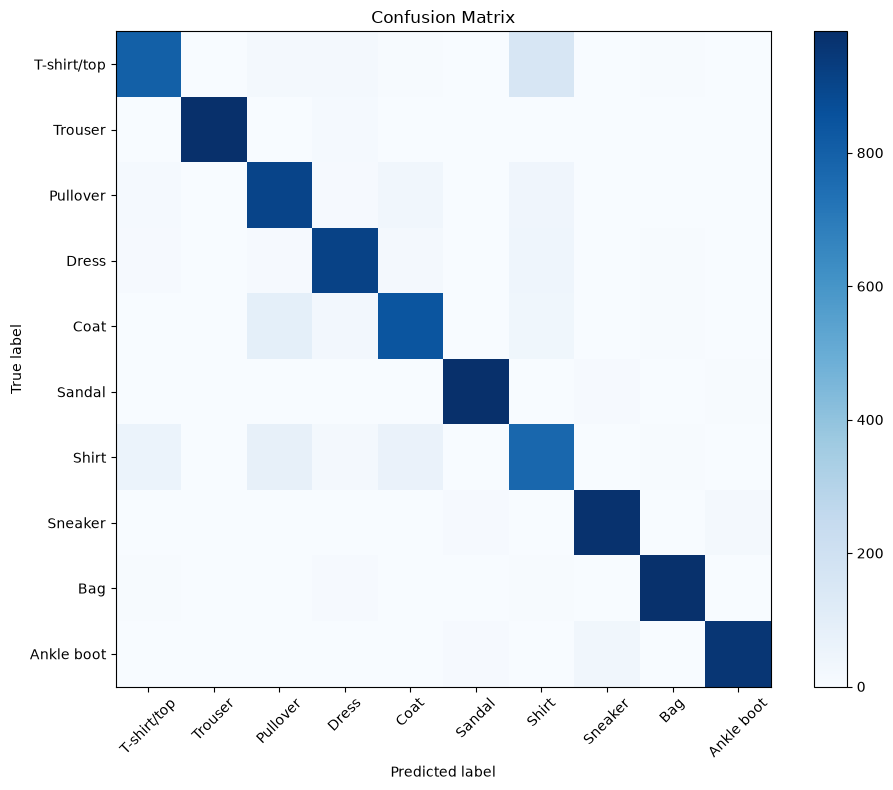

Improvement over baseline model: -0.0033 in accuracy


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

#Pick the best model based on test accuracy

best_row = results_df.sort_values("val_acc", ascending=False).iloc[0]
best_filters = int(best_row["filters"])
best_dropout = float(best_row["dropout"])
print(f"Best model has {best_filters} filters and dropout rate of {best_dropout}")

Final_model = build_cnn_model(best_filters, best_dropout)

#Build the best model and evaluate it

Final_model = build_cnn_model(best_filters, best_dropout)
Final_model.summary()
Final_model.fit(X_train, y_train_oh, epochs=10, batch_size=32, validation_split=0.2, verbose=0)

#Evaluate the final model on the test set

Final_loss, final_acc = Final_model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Final model test accuracy: {final_acc:.4f}")
print(f"Final model test loss: {Final_loss:.4f}")

#Extra : Generate classification report and confusion matrix

y_pred = np.argmax(Final_model.predict(X_test), axis=1)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print(classification_report(y_test, y_pred, target_names=class_names))

#Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

#Compare the performance of the final model with the baseline model

print(f"Improvement over baseline model: {final_acc - test_accuracy:.4f} in accuracy")

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here**

The final model (64 filters, no dropout) reached 90.93% test accuracy with a test loss of 0.3627, compared with 88.17% for the linear baseline and 91.26% for the simple CNN. Moving from the linear model to a convolutional one gave the clear improvement of about 2.8 percentage points, because convolutions learn local spatial patterns such as edges, textures and shapes that a single dense layer on flattened pixels cannot capture. Tuning did not improve on the simple CNN. All six experimental configurations landed between 90.83% and 91.54% test accuracy, and the final model’s retrain (90.93%) differed from its own experiment run (91.54%), so the differences are most likely random variation between training runs rather than real effects. Dropout did not improve accuracy, but it clearly reduced overfitting. With 0.5 dropout the training accuracy fell from about 0.97 to 0.98 down to about 0.92 to 0.93, and test loss dropped from about 0.30 to 0.36 down to about 0.26, while test accuracy stayed about the same. The no-dropout models also show signs of overfitting, with validation loss rising after epoch 5 while training loss kept falling. The weakest class was Shirt (F1 0.75), which the model confuses with T-shirt/top, Pullover and Coat because they look alike at 28x28 resolution, while Trouser, Sandal, Bag and Ankle boot were near perfect (F1 0.97 to 0.99). With more time, I would add more convolutional blocks, use early stopping around epoch 5 to 6, try lower dropout rates (0.2 to 0.3) and batch normalization, apply data augmentation, and repeat each configuration with several random seeds so real differences can be separated from noise.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.